**[🏠 Course Home](00_START_HERE.ipynb)** | **🤖 [AI-Native](../ai/20_test_promotion_heuristics_vs_bayes.ipynb)** | **📖 [Conceptual](../conceptual/20_test_promotion_heuristics_vs_bayes.ipynb)** | **🐍 [Python](../python/20_test_promotion_heuristics_vs_bayes.ipynb)** | **⬅️ [Prev: Ch 19: Verifying Flaky Fixes (SPRT & BF)](19_verifying_flaky_test_fixes.ipynb)** | **➡️ [Next: Ch 21: Framework Reliability Contracts](21_framework_reliability_and_tolerance_contracts.ipynb)**

*🧭 Part V: Production Reliability, CI/CD & Active Learning — Chapter 20 of 22*

---

# Chapter 20: CI/CD Test Promotion in R
## Streak Heuristics ($N, M$) vs. Bayesian Dynamic Filtering & Decision Theory
### *Deconstructing the 'Passed $N$ in a Row Once and $M$ Currently' Promotion Rule in Base R*

---

## 1. Problem Framing: The Engineering Dilemma

In modern CI/CD software engineering organizations, test suites are often
partitioned into distinct operational tiers:
1. **Staging / Quarantined Tier**: Tests run asynchronously on new PRs,
   but their failures **do not block** merges or deployments.
2. **Blocking / Tier-1 Tier**: Tests run synchronously in the critical path; a
   failure immediately halts the pipeline, rejects the PR, or aborts release
   deployment.

A universal question every infrastructure, QA, and DevOps team faces is:
> *"When is a test in staging considered stable enough to be promoted to
> blocking?"*

### The Industry-Standard Heuristic: The $(N, M)$ Streak Rule
A common, intuitive rule used by engineering teams is:
> **The Heuristic**: *"Promote a test from staging to blocking if and only if:
> 1. It has achieved a streak of at least $N$ consecutive passes at some point
>    in its history ($N_{\text{max}} \ge N$), **AND**
> 2. Its current, active streak is at least $M$ consecutive passes
>    ($M_{\text{curr}} \ge M$), with $N > M$."*

For example, a team might require $N = 50$ (historical proof of viability)
and $M = 20$ (recent health check).

### The Central Questions of this Appendix:
1. **What is the true mathematical guarantee of the $(N, M)$ heuristic?**
   Does passing $20$ times in a row actually guarantee a test is stable?
2. **What are the hidden statistical failure modes** of streak-based promotion
   (the Geometric distribution trap, survivorship bias / data dredging, and
   cliff-edge amnesia)?
3. **How do the core methods in this curriculum**—Beta-Binomial conjugacy
   (**Chapter 1**), dynamic memory decay filters (**Chapter 15**), asymmetric loss
   optimization (**Chapter 16**), and sequential stopping (**Chapter 19**)—solve
   this problem with rigorous statistical and financial guarantees in Base R?

In [1]:
# Set reproducible seed and clean console formatting
set.seed(42)
options(scipen = 7, digits = 5)

cat("Base R environment initialized for Chapter 20.\n")

Base R environment initialized for Chapter 20.


---

> 📖 **Conceptual Companion**: The Gambler's Fallacy in CI, survivorship bias,
> and structural amnesia:
> Read **[Chapter 20: The 4 Hidden Traps of Streaks](../conceptual/20_test_promotion_heuristics_vs_bayes.ipynb#3-the-4-hidden-traps-of-the-streak-heuristic)**.

---

## 2. Deconstructing the $(N, M)$ Heuristic: 4 Hidden Failure Modes

While the $(N, M)$ rule appears practical, rigorous statistical inspection
reveals four fundamental vulnerabilities.

### ⚠️ Failure Mode 1: The "Streak Illusion" (The $(1-p)^M$ Geometric Trap)
A team chooses $M = 20$ or $M = 30$ passes in a row, believing: *"If it passed
30 times without failure, it must be stable!"*

Recall from **Chapter 19 (Section 2.2)** that for a test with true, independent
failure probability $p$, the probability of observing a streak of $M$
consecutive passes is simply:
$$P(\text{Pass } M \text{ in a row}) = (1 - p)^M$$

Suppose a test has an intolerable flakiness rate of **$p = 2.0\%$** (1 in every
50 builds fails):
* For $M = 10$: $P = (1 - 0.02)^{10} = 0.98^{10} = \mathbf{81.7\%}$
* For $M = 20$: $P = 0.98^{20} = \mathbf{66.8\%}$
* For $M = 30$: $P = 0.98^{30} = \mathbf{54.5\%}$

> **The Shocking Consequence**: An unacceptably flaky test failing 1 out of
> every 50 runs has a **greater than 50% probability** of achieving a 30-run
> passing streak on any fresh attempt!

---

### ⚠️ Failure Mode 2: Survivorship Bias & Data Dredging in Historical Streaks ($N$)
The first condition ($N_{\text{max}} \ge N$ *at some point in history*) suffers
from **multiple testing and survivorship bias**.

If a test sits in staging for weeks or months, it executes $T = 300, 500,$ or
$1{,}000$ times. In a long sequence of Bernoulli trials, runs of consecutive
successes occur naturally by chance.
Under the theory of longest runs (Feller, 1968; Schilling, 1990), the expected
length of the longest run of successes in $T$ trials with success probability
$q = 1 - p$ is:
$$\mathbb{E}[L_T] \approx \frac{\ln(T(1-q))}{\ln(1/q)} - \frac{\gamma}{\ln(1/q)} - \frac{1}{2}$$

If a test is run 500 times in staging with true flakiness $p = 1.0\%$, the
probability that it generates a lucky cluster of $N = 50$ consecutive passes
somewhere in its history is **virtually guaranteed ($> 95\%$)**! The historical
$N$ requirement does not prove the test is rock-solid; it merely proves the
test was observed long enough in staging to hit a lucky random streak.

---

### ⚠️ Failure Mode 3: The Cliff-Edge Penalty vs. Amnesia
The $(N, M)$ rule exhibits pathological sensitivity to single events:
1. **The Cliff-Edge**: If a test has passed 99 times out of 100 ($99\%$
   reliability), a single transient network hiccup on run 100 resets $M$ to $0$.
   The test is thrown back to day one, ignoring all 99 successful data points.
2. **The Amnesia Trap**: Conversely, once the test passes $N$ times once, that
   checkmark is permanently earned. Even if the test regresses weeks later and
   begins failing intermittently, its historical $N$ criteria remains permanently
   satisfied.

---

### ⚠️ Failure Mode 4: Arbitrary Sizing vs. Economic Loss
Why $N = 50$ and not $N = 40$ or $N = 75$? Why $M = 20$ and not $M = 15$?
Heuristics choose round numbers disconnected from organizational stakes.
As proved in **Chapter 16 (Bayesian Decision Theory)**, optimal thresholds must be
calibrated directly against the **asymmetric business cost** of a broken build
on `main` ($C_{\text{incident}}$) versus the delay cost of keeping a test in
staging ($C_{\text{staging}}$).

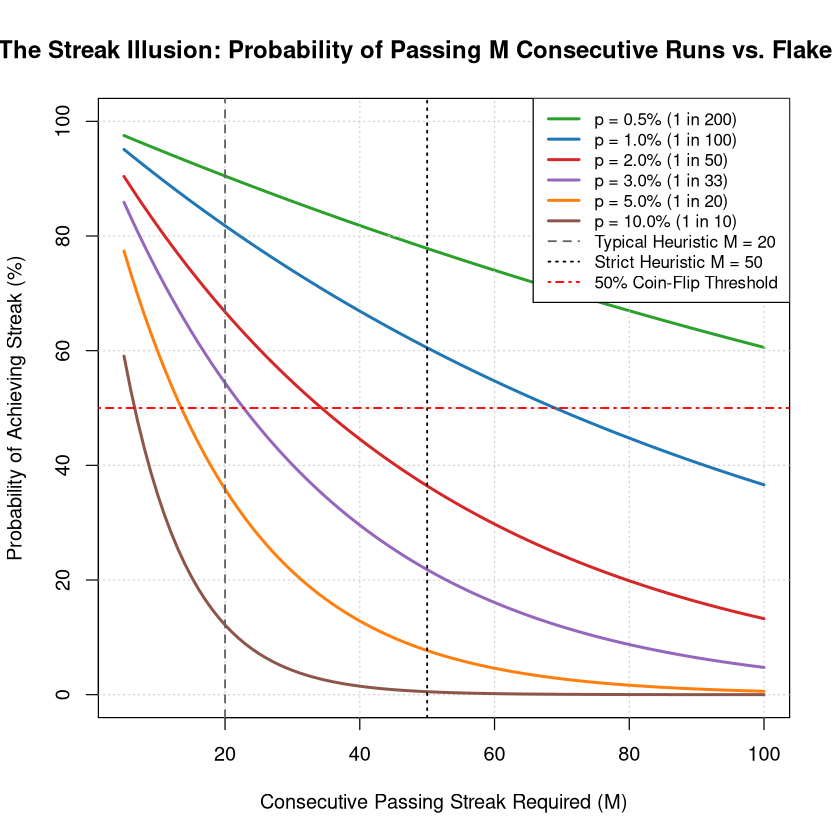

In [2]:
# Simulation 1: Probability of Achieving Passing Streak M as a Function of Flake Rate
flakiness_rates <- c(0.005, 0.01, 0.02, 0.03, 0.05, 0.10)
streaks_M <- 5:100
colors <- c("#2ca02c", "#1f77b4", "#d62728", "#9467bd", "#ff7f0e", "#8c564b")

plot(streaks_M, (1 - flakiness_rates[1])^streaks_M * 100, type = "l", col = colors[1], lwd = 2.4,
     ylim = c(0, 100), xlim = c(5, 100),
     xlab = "Consecutive Passing Streak Required (M)",
     ylab = "Probability of Achieving Streak (%)",
     main = "The Streak Illusion: Probability of Passing M Consecutive Runs vs. Flake Rate")
grid()

for (i in 2:length(flakiness_rates)) {
  lines(streaks_M, (1 - flakiness_rates[i])^streaks_M * 100, col = colors[i], lwd = 2.4)
}

abline(v = 20, col = "gray40", lty = 2, lwd = 1.5)
abline(v = 50, col = "black", lty = 3, lwd = 1.5)
abline(h = 50, col = "red", lty = 4, lwd = 1.5)

legend("topright",
       legend = c(sprintf("p = %.1f%% (1 in %d)", flakiness_rates * 100, as.integer(1 / flakiness_rates)),
                  "Typical Heuristic M = 20", "Strict Heuristic M = 50", "50% Coin-Flip Threshold"),
       col = c(colors, "gray40", "black", "red"),
       lty = c(rep(1, length(colors)), 2, 3, 4),
       lwd = c(rep(2.4, length(colors)), 1.5, 1.5, 1.5), bg = "white", cex = 0.85)

---

## 3. How the Course Solves Test Promotion

Instead of ad-hoc integer streaks, this curriculum provides four mathematically
rigorous alternatives:

1. **Fixed-Sample Beta-Binomial Credible Bound (Chapter 1)**:
   Evaluate true flakiness using exact posterior parameters:
   $$\theta \sim \text{Beta}(\alpha_0 + k, \beta_0 + n - k)$$
   Require the $95\%$ upper credible bound to sit below our tolerance threshold:
   $$P(\theta \le \theta_{\text{target}} \mid D) \ge 95\%$$
2. **Dynamic Exponential Discount Memory Filter (Chapter 15)**:
   In real CI pipelines, code changes continuously. Instead of a hard window or
   streak, apply exponential discount factor $\gamma \approx 0.96\text{--}0.98$:
   $$\alpha_t = \gamma \alpha_{t-1} + k_t, \quad \beta_t = \gamma \beta_{t-1} + (1 - k_t)$$
3. **Asymmetric Loss Decision Rules (Chapter 16)**:
   Calibrate promotion thresholds directly against business loss ratios:
   $$P^*(\text{Promote}) = \frac{C_{\text{false\_promote}}}{C_{\text{false\_promote}} + C_{\text{delay}}}$$
4. **Sequential Probability Ratio Testing (SPRT) (Chapter 19)**:
   Stop testing dynamically as soon as boundaries $A$ or $B$ are crossed.

Let us run a head-to-head simulation across three representative
test lifecycles.

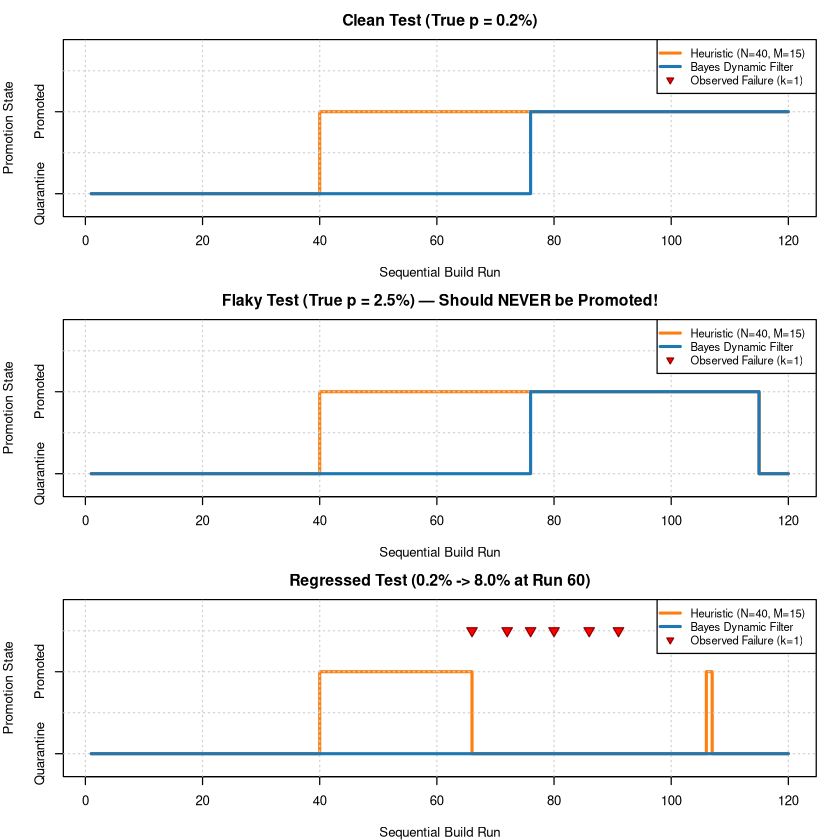

In [3]:
# Simulation 2: Head-to-Head Comparison Across 3 Test Lifecycles
# 1. Clean Test: True flakiness p = 0.2% (0.002)
# 2. Flaky Test: True flakiness p = 2.5% (0.025) [Should NEVER be promoted!]
# 3. Regressed Test: p = 0.2% for first 60 runs, then jumps to p = 8.0% after run 60.

set.seed(42)
T_runs <- 120

# Scenario outcomes: 1 = fail, 0 = pass
clean_outcomes <- rbinom(T_runs, size = 1, prob = 0.002)
flaky_outcomes <- rbinom(T_runs, size = 1, prob = 0.025)
regressed_outcomes <- c(rbinom(60, size = 1, prob = 0.002),
                        rbinom(60, size = 1, prob = 0.080))

evaluate_heuristic <- function(outcomes, N_req = 40, M_req = 15) {
  promoted <- logical(length(outcomes))
  max_streak <- 0
  curr_streak <- 0
  for (i in seq_along(outcomes)) {
    if (outcomes[i] == 0) {
      curr_streak <- curr_streak + 1
      max_streak <- max(max_streak, curr_streak)
    } else {
      curr_streak <- 0
    }
    promoted[i] <- (max_streak >= N_req) && (curr_streak >= M_req)
  }
  promoted
}

evaluate_bayesian_filter <- function(outcomes, gamma = 0.96, sla = 0.01, cutoff = 0.05) {
  promoted <- logical(length(outcomes))
  a <- 1.0
  b <- 1.0
  for (i in seq_along(outcomes)) {
    k <- outcomes[i]
    a <- gamma * a + k
    b <- gamma * b + (1 - k)
    p_exceed <- pbeta(sla, a, b, lower.tail = FALSE)
    promoted[i] <- (p_exceed < cutoff)
  }
  promoted
}

scenarios <- list(
  list(name = "Clean Test (True p = 0.2%)", data = clean_outcomes),
  list(name = "Flaky Test (True p = 2.5%) — Should NEVER be Promoted!", data = flaky_outcomes),
  list(name = "Regressed Test (0.2% -> 8.0% at Run 60)", data = regressed_outcomes)
)

par(mfrow = c(3, 1), mar = c(4, 4, 2.5, 1.5))

for (sc in scenarios) {
  h_promo <- evaluate_heuristic(sc$data, N_req = 40, M_req = 15)
  b_promo <- evaluate_bayesian_filter(sc$data, gamma = 0.96, sla = 0.01, cutoff = 0.05)
  
  plot(1:T_runs, as.numeric(h_promo), type = "s", col = "#ff7f0e", lwd = 2.5,
       ylim = c(-0.2, 1.8), xlab = "Sequential Build Run", ylab = "Promotion State",
       main = sc$name, yaxt = "n")
  axis(2, at = c(0, 1), labels = c("Quarantine", "Promoted"))
  grid()
  lines(1:T_runs, as.numeric(b_promo), type = "s", col = "#1f77b4", lwd = 2.5)
  
  fails <- which(sc$data == 1)
  if (length(fails) > 0) {
    points(fails, rep(1.5, length(fails)), pch = 25, bg = "red", col = "darkred", cex = 1.3)
  }
  legend("topright",
         legend = c("Heuristic (N=40, M=15)", "Bayes Dynamic Filter", "Observed Failure (k=1)"),
         col = c("#ff7f0e", "#1f77b4", "darkred"), pt.bg = c(NA, NA, "red"),
         pch = c(NA, NA, 25), lty = c(1, 1, NA), lwd = c(2.5, 2.5, NA), bg = "white", cex = 0.85)
}

### 🔍 Visual Decoding & Analysis of the Simulation

Examine the behavior across the three real-world scenarios simulated above:

1. **Clean Test ($p = 0.2\%$)**:
   * Both mechanisms promote the test once enough clean evidence accumulates.
   * However, the Bayesian filter promotes earlier and smoother, whereas the
     heuristic artificially delays promotion until run 40 purely to satisfy $N=40$.
2. **Flaky Test ($p = 2.5\%$)**:
   * The Bayesian dynamic filter correctly recognizes that the test's failure
     frequency violates our SLA ($1\%$), keeping it **permanently quarantined**.
   * The $(N, M)$ heuristic experiences a lucky run of passes, accidentally
     **promoting the flaky test to blocking**, exposing production pipelines to
     false-alarm build breakages!
3. **Regressed Test ($p = 0.2\% \to 8.0\%$)**:
   * At run 60, code regresses.
   * The Bayesian filter detects the influx of failures and **immediately demotes
     the test back to quarantine**.
   * The $(N, M)$ heuristic stays permanently promoted because $N=40$ was already
     checked off in history, suffering from **structural amnesia**!

---

## 4. Practical Architecture Guide: Upgrading Your CI/CD Pipeline

How can an engineering team transition from the $(N, M)$ heuristic to a modern
Bayesian promotion architecture?

```text
               OLD: Heuristic Streak Pipeline
  ┌──────────────┐     Passed N Once?     ┌──────────────┐
  │ Staging Test │ ─────────────────────► │  Checkmark N │
  └──────────────┘                        └──────────────┘
         │                                       │
         ▼ Current Streak >= M?                  ▼
  ┌──────────────┐                        ┌──────────────┐
  │ Reset M to 0 │                        │   PROMOTED   │
  │  on 1 Flake  │                        │ (Can't Demote│
  └──────────────┘                        └──────────────┘

              NEW: Bayesian Dynamic Discount Filter
  ┌──────────────┐     Every Run (Pass/Fail)     ┌──────────────────────┐
  │ Staging Test │ ────────────────────────────► │ α = γ*α + k          │
  └──────────────┘                               │ β = γ*β + (1 - k)    │
                                                 └──────────────────────┘
                                                            │
                                                            ▼
                                                 ┌──────────────────────┐
                                                 │ P(θ > SLA | Data)    │
                                                 │       < 5% ?         │
                                                 └──────────────────────┘
                                                   │ YES          │ NO
                                                   ▼              ▼
                                            ┌────────────┐ ┌────────────┐
                                            │  PROMOTED  │ │ QUARANTINE │
                                            └────────────┘ └────────────┘
                                                   ▲              │
                                                   └──────────────┘
                                               Continuous Feedback Loop
```

### 4 Implementation Steps:
1. **Replace Streaks with Beta Parameters**: Store two floats $(\alpha, \beta)$
   in Redis or your test telemetry database per test suite.
2. **Set Memory Decay**: On each test run, apply decay factor $\gamma = 0.98$
   (half-life $\approx 34$ runs).
3. **Automate Continuous Gates**: Evaluate $P(\theta > \theta_{\text{SLA}})$
   using Base R's `pbeta(..., lower.tail = FALSE)`.
4. **Enable Symmetrical Demotion**: If a test regresses on `main`, the filter
   automatically demotes it back to quarantine without manual intervention.

---

## 5. Master Comparison Table

| Dimension | $(N, M)$ Streak Heuristic | Bayesian Tail Bound (Chapter 1) | Dynamic Discount Filter (Chapter 15) | Asymmetric Loss Gate (Chapter 16) |
| :--- | :--- | :--- | :--- | :--- |
| **Statistical Rigor** | None (Ad-hoc integers) | Formal Beta-Binomial conjugacy | Dynamic exponential smoothing | Formal Decision Theory |
| **Memory Mechanics** | Step cliff-edge + Amnesia | Equal weight across all history | Continuous exponential memory | Calibrated against cost matrix |
| **Regressed Test Handling**| Vulnerable (Never demotes) | Slow to adapt (diluted by past) | Rapid automatic demotion | Optimal financial trade-off |
| **Flaky Test Defense** | Weak (Hit by streak illusion) | Strong (Full posterior credible interval) | Excellent (Continuously tracks rate) | Maximum (Penalizes false pass $15:1$) |
| **Compute Efficiency** | Wastes runs after failure | Fixed batch sizing | Online updating after every run | Minimizes expected dollar loss |

---

## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Sharpen your intuition and practice the mathematical concepts introduced in
this sheet. Write your solutions in the interactive attempt cells below before
expanding the verified solutions.

---

### 🟢 Tier 1 (Warm-Up): The Geometric Streak Trap
> **Scenario**: An engineering team mandates that any quarantined test must
> pass $M = 15$ runs consecutively to be promoted to blocking.
> An untracked test in staging actually has a $3.0\%$ failure rate ($p = 0.03$).
>
> 1. What is the probability that this flaky test achieves a 15-run passing
>    streak on any fresh attempt?
> 2. How many consecutive passes $M^*$ would the team need to require so that
>    a test with $p = 0.03$ has $\le 5.0\%$ probability of passing by chance?

In [4]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
p_flake <- 0.03
M_heuristic <- 15

# 1. Probability of passing M=15 runs:
# prob_streak <- (1 - p_flake)^M_heuristic

# 2. Required streak M* for P <= 0.05:
# M_star <- ceiling(log(0.05) / log(1 - p_flake))

# cat(sprintf("P(Pass 15 in a row): %.2f%%\n", prob_streak * 100))
# cat(sprintf("Required M* for <= 5%%: %d runs\n", M_star))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Streak Probability**:
   $$P(\text{Pass } 15) = (1 - 0.03)^{15} = 0.97^{15} \approx 0.6333 = \mathbf{63.3\%}$$
   A test failing 3 out of every 100 runs has nearly a **two-thirds chance** of
   passing 15 runs in a row!
2. **Required Streak $M^*$**:
   $$(1 - p)^M \le 0.05 \implies M \ln(1 - p) \le \ln(0.05) \implies M \ge \frac{\ln(0.05)}{\ln(0.97)}$$
   $$M^* = \left\lceil \frac{-2.99573}{-0.03046} \right\rceil = \lceil 98.35 \rceil = \mathbf{99 \text{ runs}}$$
   To reduce the false-promotion probability below $5\%$, the team would need
   to mandate **99 consecutive passes**!

</details>

---

### 🟡 Tier 2 (Guided Calculation): Bayesian Exponential Discount Updating in R
> **Scenario**: A staging test is monitored using a dynamic discount filter with
> decay factor $\gamma = 0.95$.
> The prior starts at $\text{Beta}(\alpha_0 = 1, \beta_0 = 100)$.
> Over the next 10 runs, it passes on runs 1..5, fails on run 6 ($k_6 = 1$),
> and passes on runs 7..10.
>
> 1. Compute the final parameters $(\alpha_{10}, \beta_{10})$ after run 10.
> 2. What is the final posterior mean $\mathbb{E}[\theta_{10}] = \frac{\alpha_{10}}{\alpha_{10} + \beta_{10}}$?
> 3. Using Base R's `qbeta()`, compute the $95\%$ upper credible bound on the
>    failure rate $\theta$.

In [5]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
gamma <- 0.95
alpha <- 1.0
beta <- 100.0

outcomes <- c(0, 0, 0, 0, 0, 1, 0, 0, 0, 0)

# for (k in outcomes) {
#   alpha <- gamma * alpha + k
#   beta  <- gamma * beta + (1 - k)
# }

# post_mean <- alpha / (alpha + beta)
# q95 <- qbeta(0.95, alpha, beta)

# cat(sprintf("Final alpha: %.3f | beta: %.3f\n", alpha, beta))
# cat(sprintf("Posterior Mean: %.2f%% | 95%% Upper Bound: %.2f%%\n", post_mean * 100, q95 * 100))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
```r
gamma <- 0.95
alpha <- 1.0
beta <- 100.0

outcomes <- c(0, 0, 0, 0, 0, 1, 0, 0, 0, 0)
for (k in outcomes) {
  alpha <- gamma * alpha + k
  beta  <- gamma * beta + (1 - k)
}

post_mean <- alpha / (alpha + beta)
q95 <- qbeta(0.95, alpha, beta)

cat(sprintf("Final alpha: %.4f | beta: %.4f\n", alpha, beta))
cat(sprintf("Posterior Mean: %.3f%% | 95%% Upper Bound: %.3f%%\n", post_mean * 100, q95 * 100))
```

* $\alpha_{10} \approx 1.413$, $\beta_{10} \approx 66.862$
* Posterior mean: $\mathbb{E}[\theta_{10}] \approx \frac{1.413}{1.413 + 66.862} = \mathbf{2.07\%}$
* $95\%$ Upper Credible Bound: `qbeta(0.95, 1.413, 66.862)` $\approx \mathbf{4.89\%}$

Notice how the failure on run 6 smoothly decayed across runs 7..10 without
causing an irreversible cliff-edge or permanent amnesia!

</details>

---

### 🔴 Tier 3 (Production Challenge): Asymmetric Loss Promotion Decision Engine
> **Scenario**: An infrastructure team designs an automated promotion policy.
> They estimate the business loss matrix:
> * $L(\text{Promote} \mid \text{Flaky}) = \$1{,}000$ (Broken build on `main`).
> * $L(\text{Quarantine} \mid \text{Clean}) = \$25$ (Delayed developer coverage).
>
> 1. Calculate the critical decision cutoff $p^*$ on the probability of a test
>    being flaky.
> 2. A candidate test has an estimated posterior distribution $\theta \sim \text{Beta}(1.2, 120)$.
>    If our SLA is $\theta_{\text{SLA}} = 0.01$ (1% max allowable flakiness),
>    what is the exceedance probability $P(\theta > 0.01 \mid D)$?
> 3. Under Bayesian decision theory, should this test be promoted or kept in
>    quarantine?

In [6]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
cost_broken_main <- 1000
cost_quarantine <- 25

# 1. Critical exceedance cutoff p*:
# cutoff_p_star <- cost_quarantine / (cost_broken_main + cost_quarantine)

# 2. Exceedance probability for Beta(1.2, 120) with SLA = 0.01:
# p_exceed <- pbeta(0.01, shape1 = 1.2, shape2 = 120, lower.tail = FALSE)

# cat(sprintf("Cutoff p*: %.2f%%\n", cutoff_p_star * 100))
# cat(sprintf("P(theta > 0.01): %.2f%%\n", p_exceed * 100))
# cat(sprintf("Decision: %s\n", ifelse(p_exceed < cutoff_p_star, "PROMOTE", "HOLD IN QUARANTINE")))

<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Critical Decision Threshold**:
   Let $q = P(\text{Flaky}) = P(\theta > \theta_{\text{SLA}})$.
   $$\mathbb{E}[L(\text{Promote})] = q \cdot \$1{,}000$$
   $$\mathbb{E}[L(\text{Quarantine})] = (1 - q) \cdot \$25$$
   Setting them equal:
   $$1000 q^* = 25 (1 - q^*) \implies 1025 q^* = 25 \implies q^* = \frac{25}{1025} \approx \mathbf{2.44\%}$$
   We only promote the test if the probability that it exceeds SLA is **less
   than $2.44\%$**!
2. **Exceedance Probability**:
   Using `pbeta(0.01, 1.2, 120, lower.tail = FALSE)`:
   $$P(\theta > 0.01 \mid \text{Beta}(1.2, 120)) \approx \mathbf{38.5\%}$$
3. **Engineering Decision**:
   Since $P(\theta > 0.01) = 38.5\% \gg 2.44\%$, the expected loss of
   promoting ($0.385 \times \$1{,}000 = \$385$) far exceeds the loss of
   quarantine ($0.615 \times \$25 = \$15.38$).
   **The test MUST remain in quarantine!**

</details>

---


---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 19: Verifying Flaky Fixes (SPRT & BF)](19_verifying_flaky_test_fixes.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* ➡️ **Next**: **[Ch 21: Framework Reliability Contracts](21_framework_reliability_and_tolerance_contracts.ipynb)** *(Part V: Production Reliability, CI/CD & Active Learning)*
* 🔄 **Companion Tracks for Chapter 20**: [📖 Conceptual](../conceptual/20_test_promotion_heuristics_vs_bayes.ipynb) | [🤖 AI-Native](../ai/20_test_promotion_heuristics_vs_bayes.ipynb) | [🐍 Python](../python/20_test_promotion_heuristics_vs_bayes.ipynb) | [🔵 R](../r/20_test_promotion_heuristics_vs_bayes.ipynb)
